In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import os,json

In [2]:
# get config information
utils_dir = '../utils/'

with open(os.path.join(utils_dir, "biome_info.json"), "r") as f:
    biome_info = json.load(f)

### Biome mean scatter plots

In [5]:
obs = xr.open_dataset('../utils/obs_statistics_byBiome.nc')

In [6]:
### Load Latin Hypercube sample post processed data
ds_lhc = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/postp/ctsm53065_lhc_biome_1850-2023.nc')
# subset and average over years
lai_biome_lhc = ds_lhc.TLAI_biome_amax.sel(year=slice('2001','2020')).mean(dim='year')
tvc_biome_lhc = (1/1000)*ds_lhc.TOTVEGC_biome_amean.sel(year=slice('2000','2019')).mean(dim='year')
gpp_biome_lhc = (86400)*ds_lhc.GPP_biome_amean.sel(year=slice('2001','2017')).mean(dim='year')
lh_biome_lhc = ds_lhc.EFLX_LH_TOT_biome_amean.sel(year=slice('2000','2014')).mean(dim='year')

In [7]:
### Load Wave1
ds_wave1 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave1/postp/ctsm53065_wave1_biome_1850-2023.nc')
# subset and average over years
lai_biome_wave1 = ds_wave1.TLAI_biome_amax.sel(year=slice('2001','2020')).mean(dim='year')
tvc_biome_wave1 = (1/1000)*ds_wave1.TOTVEGC_biome_amean.sel(year=slice('2000','2019')).mean(dim='year')
gpp_biome_wave1 = (86400)*ds_wave1.GPP_biome_amean.sel(year=slice('2001','2017')).mean(dim='year')
lh_biome_wave1 = ds_wave1.EFLX_LH_TOT_biome_amean.sel(year=slice('2000','2014')).mean(dim='year')

In [8]:
### Load Wave2
ds_wave2 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave2/postp/ctsm53065_wave2_biome_1850-2023.nc')
# subset and average over years
lai_biome_wave2 = ds_wave2.TLAI_biome_amax.sel(year=slice('2001','2020')).mean(dim='year')
tvc_biome_wave2 = (1/1000)*ds_wave2.TOTVEGC_biome_amean.sel(year=slice('2000','2019')).mean(dim='year')
gpp_biome_wave2 = (86400)*ds_wave2.GPP_biome_amean.sel(year=slice('2001','2017')).mean(dim='year')
lh_biome_wave2 = ds_wave2.EFLX_LH_TOT_biome_amean.sel(year=slice('2000','2014')).mean(dim='year')

In [9]:
### Load Wave3
ds_wave3 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave3/postp/ctsm53065_wave3_biome_1850-2023.nc')
# subset and average over years
lai_biome_wave3 = ds_wave3.TLAI_biome_amax.sel(year=slice('2001','2020')).mean(dim='year')
tvc_biome_wave3 = (1/1000)*ds_wave3.TOTVEGC_biome_amean.sel(year=slice('2000','2019')).mean(dim='year')
gpp_biome_wave3 = (86400)*ds_wave3.GPP_biome_amean.sel(year=slice('2001','2017')).mean(dim='year')
lh_biome_wave3 = ds_wave3.EFLX_LH_TOT_biome_amean.sel(year=slice('2000','2014')).mean(dim='year')

In [10]:
### Load Wave4
ds_wave4 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave4/postp/ctsm53065_wave4_biome_1850-2023.nc')
# subset and average over years
lai_biome_wave4 = ds_wave4.TLAI_biome_amax.sel(year=slice('2001','2020')).mean(dim='year')
tvc_biome_wave4 = (1/1000)*ds_wave4.TOTVEGC_biome_amean.sel(year=slice('2000','2019')).mean(dim='year')
gpp_biome_wave4 = (86400)*ds_wave4.GPP_biome_amean.sel(year=slice('2001','2017')).mean(dim='year')
lh_biome_wave4 = ds_wave4.EFLX_LH_TOT_biome_amean.sel(year=slice('2000','2014')).mean(dim='year')

In [11]:
### Load HMC
ds_hmc = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_hmc/postp/ctsm53065_hmc_biome_1850-2023.nc')
# subset and average over years
lai_biome_hmc = ds_hmc.TLAI_biome_amax.sel(year=slice('2001','2020')).mean(dim='year')
tvc_biome_hmc = (1/1000)*ds_hmc.TOTVEGC_biome_amean.sel(year=slice('2000','2019')).mean(dim='year')
gpp_biome_hmc = (86400)*ds_hmc.GPP_biome_amean.sel(year=slice('2001','2017')).mean(dim='year')
lh_biome_hmc = ds_hmc.EFLX_LH_TOT_biome_amean.sel(year=slice('2000','2014')).mean(dim='year')

# Plot all biomes

In [12]:
pal = sns.cubehelix_palette(9, start=2.5, rot=-0.5, light=.8, dark=0.01)
colors = ['grey', pal[8], pal[6], pal[4], pal[1], 'slateblue', '#8B008B']

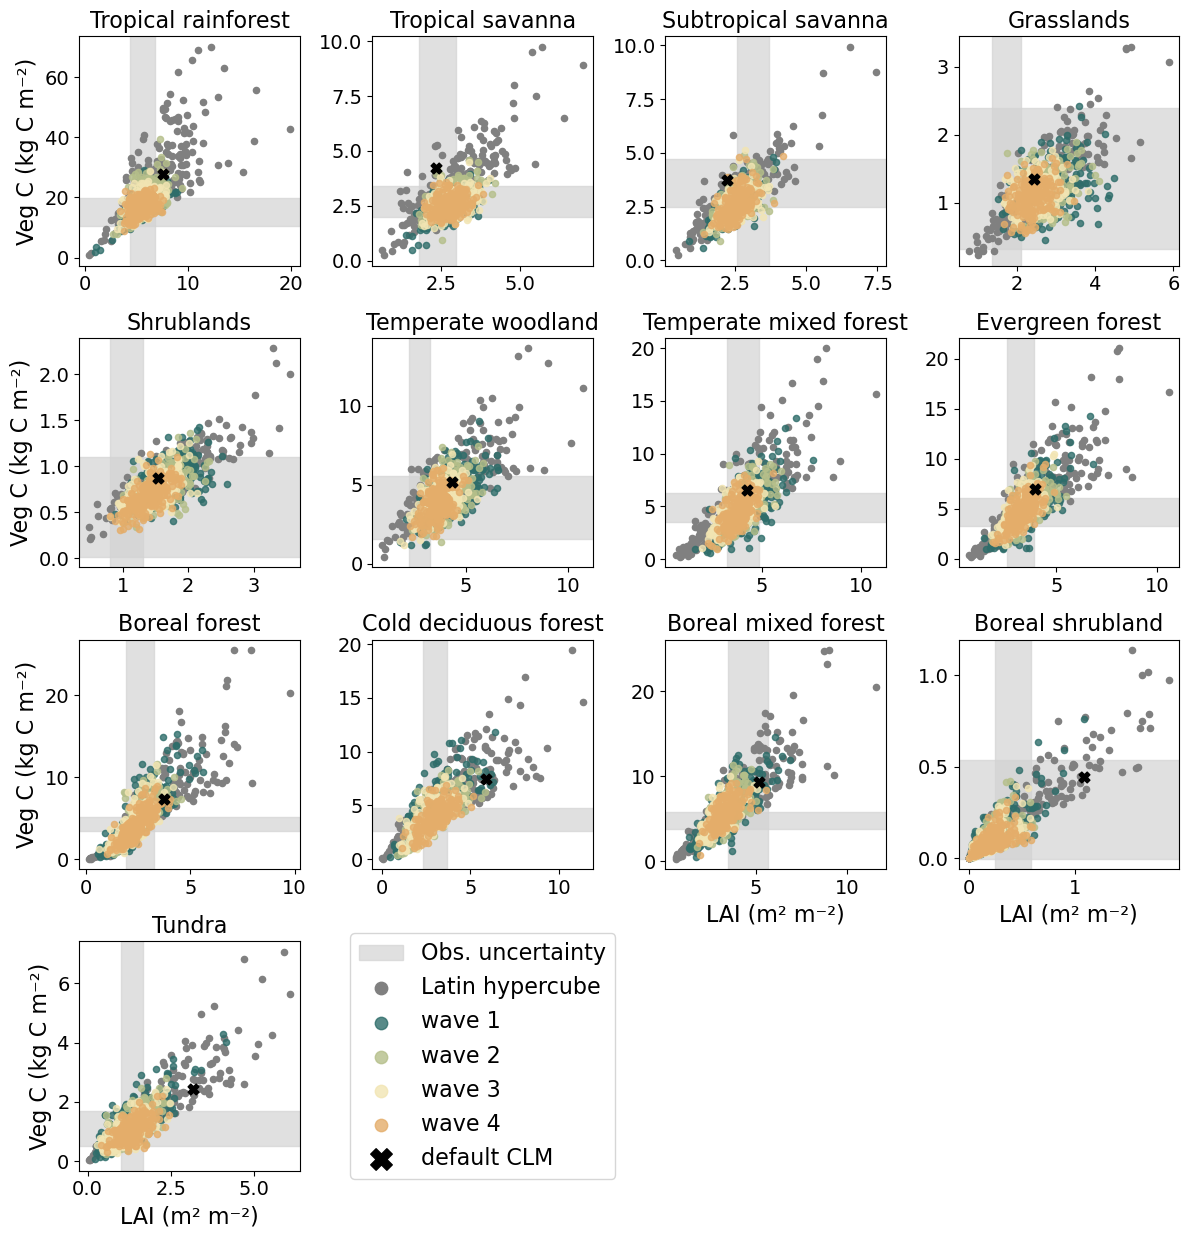

In [13]:
colors = ['grey','#2E6D6A', '#B5BF8A','#F2E5B3', '#E4AD6A','slateblue','k']

plt.figure(figsize=(12,13))

for b in range(1,14):
    plt.subplot(4,4,b)
    
    # Observation uncertainty as shaded region
    plt.axvspan(obs.LAI_mean.isel(biome=b)-3*obs.LAI_stdev.isel(biome=b),
                obs.LAI_mean.isel(biome=b)+3*obs.LAI_stdev.isel(biome=b),
                alpha=0.7, color='lightgrey', label='Obs. uncertainty' if b==1 else '')
    plt.axhspan(obs.TVC_mean.isel(biome=b)-3*obs.TVC_stdev.isel(biome=b),
                obs.TVC_mean.isel(biome=b)+3*obs.TVC_stdev.isel(biome=b),
                alpha=0.7, color='lightgrey')

    # Model ensemble results
    plt.scatter(lai_biome_lhc.isel(biome=b), tvc_biome_lhc.isel(biome=b),
                color=colors[0], s=20, alpha=1, label='Latin hypercube' if b==1 else '')
    plt.scatter(lai_biome_wave1.isel(biome=b), tvc_biome_wave1.isel(biome=b),
                color=colors[1], s=20, alpha=0.8, label='wave 1' if b==1 else '')
    plt.scatter(lai_biome_wave2.isel(biome=b), tvc_biome_wave2.isel(biome=b),
                color=colors[2], s=20, alpha=0.8, label='wave 2' if b==1 else '')
    plt.scatter(lai_biome_wave3.isel(biome=b), tvc_biome_wave3.isel(biome=b),
                color=colors[3], s=20, alpha=0.8, label='wave 3' if b==1 else '')
    plt.scatter(lai_biome_wave4.isel(biome=b), tvc_biome_wave4.isel(biome=b),
                color=colors[4], s=20, alpha=0.8, label='wave 4' if b==1 else '')
    #plt.scatter(lai_biome_hmc.isel(biome=b), tvc_biome_hmc.isel(biome=b),
    #            color=colors[5], s=20, alpha=0.6, label='hmc' if b==1 else '')
    # Default model
    plt.scatter(lai_biome_lhc.isel(biome=b, ens=0), tvc_biome_lhc.isel(biome=b, ens=0),
                color=colors[6], s=60, marker='X', zorder=5, label='default CLM' if b==1 else '')

    plt.title(biome_info[str(b)]['name'], fontsize=16)
    plt.tick_params(labelsize=14)

    # Only label outer edges
    if (b>10):
        plt.xlabel('LAI (m² m⁻²)', fontsize=16)
    if ((b-1)%4 == 0):
        plt.ylabel('Veg C (kg C m⁻²)', fontsize=16)


# Get legend handles and labels from the first subplot (3,5,1)
ax1 = plt.subplot(4,4,1)
handles, labels = ax1.get_legend_handles_labels()

# Place legend in the empty subplot (3,5,14)
plt.subplot(4,4,14)
plt.axis('off')
plt.legend(handles, labels, loc='center', ncol=1, fontsize=16, frameon=True, markerscale=2)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('../figs/SI_figureS6_LAIvVEGC_hm.png', dpi=300, bbox_inches='tight')

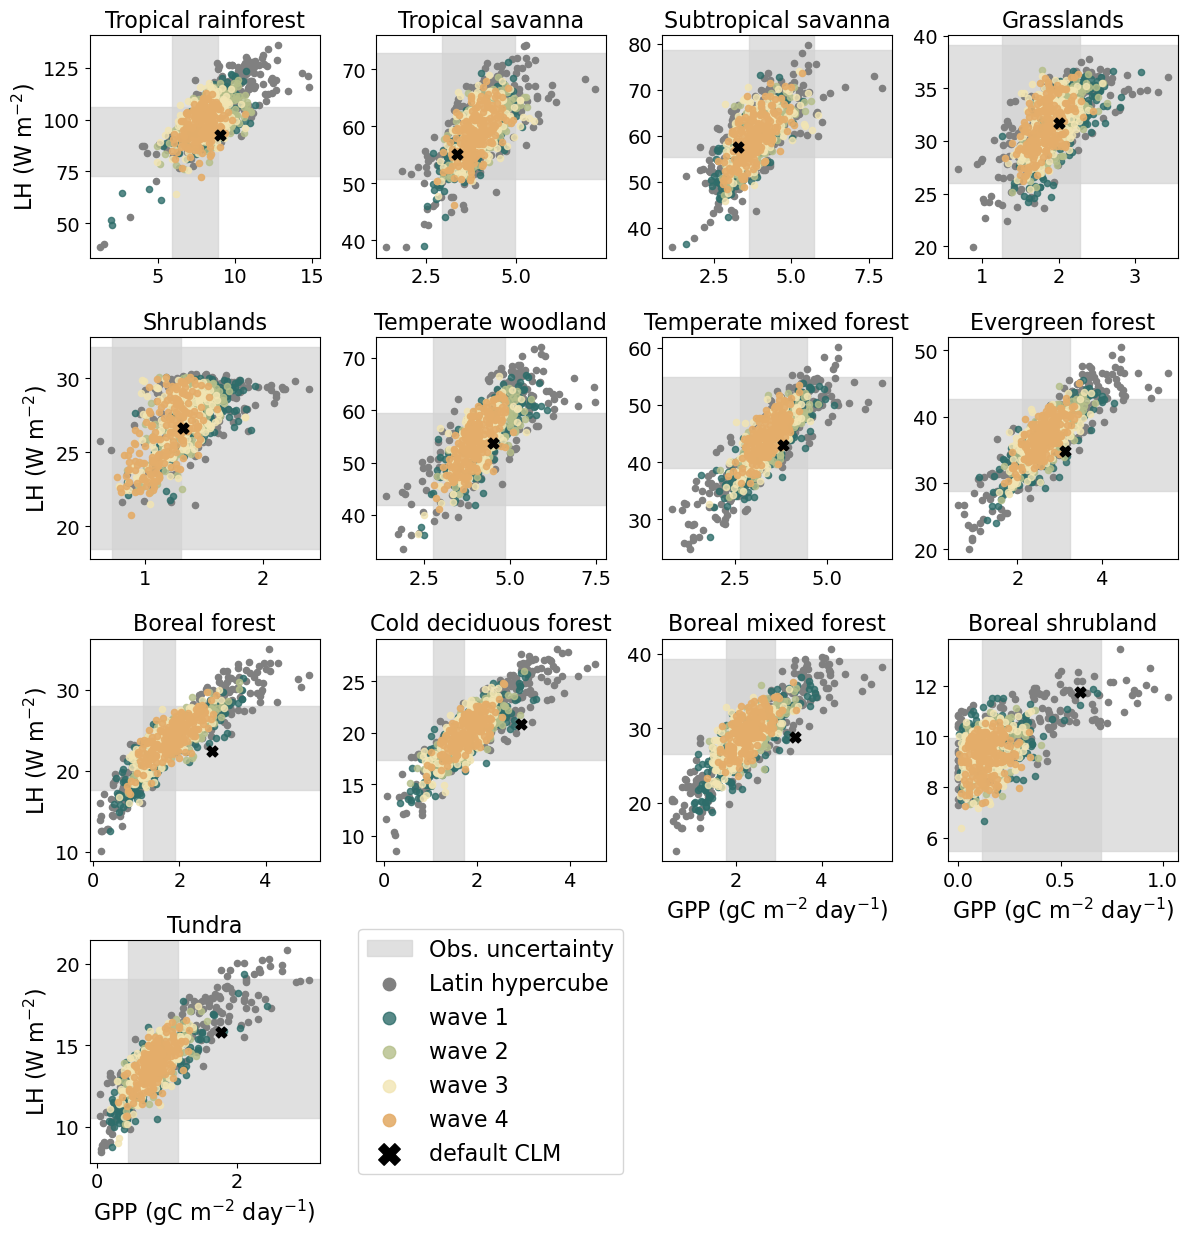

In [14]:
colors = ['grey','#2E6D6A', '#B5BF8A','#F2E5B3', '#E4AD6A','slateblue','k']

plt.figure(figsize=(12,13))
for b in range(1,14):
    plt.subplot(4,4,b)
    
    # Observation uncertainty as shaded region
    plt.axvspan(obs.GPP_mean.isel(biome=b)-3*obs.GPP_stdev.isel(biome=b),
                obs.GPP_mean.isel(biome=b)+3*obs.GPP_stdev.isel(biome=b),
                alpha=0.7, color='lightgrey', label='Obs. uncertainty' if b==1 else '')
    plt.axhspan(obs.LH_mean.isel(biome=b)-3*obs.LH_stdev.isel(biome=b),
                obs.LH_mean.isel(biome=b)+3*obs.LH_stdev.isel(biome=b),
                alpha=0.7, color='lightgrey')

    # Model ensemble results
    plt.scatter(gpp_biome_lhc.isel(biome=b), lh_biome_lhc.isel(biome=b),
                color=colors[0], s=20, alpha=1, label='Latin hypercube' if b==1 else '')
    plt.scatter(gpp_biome_wave1.isel(biome=b), lh_biome_wave1.isel(biome=b),
                color=colors[1], s=20, alpha=0.8, label='wave 1' if b==1 else '')
    plt.scatter(gpp_biome_wave2.isel(biome=b), lh_biome_wave2.isel(biome=b),
                color=colors[2], s=20, alpha=0.8, label='wave 2' if b==1 else '')
    plt.scatter(gpp_biome_wave3.isel(biome=b), lh_biome_wave3.isel(biome=b),
                color=colors[3], s=20, alpha=0.8, label='wave 3' if b==1 else '')
    plt.scatter(gpp_biome_wave4.isel(biome=b), lh_biome_wave4.isel(biome=b),
                color=colors[4], s=20, alpha=0.9, label='wave 4' if b==1 else '')   
    #plt.scatter(gpp_biome_hmc.isel(biome=b), lh_biome_hmc.isel(biome=b),
    #            color=colors[5], s=20, alpha=0.6, label='hmc' if b==1 else '')  
    # Default model
    plt.scatter(gpp_biome_lhc.isel(biome=b, ens=0), lh_biome_lhc.isel(biome=b, ens=0),
                color=colors[6], s=60, marker='X', zorder=5, label='default CLM')

    plt.title(biome_info[str(b)]['name'], fontsize=16)
    plt.tick_params(labelsize=14)

    # Only label outer edges
    if (b>10):
        plt.xlabel('GPP (gC m$^{-2}$ day$^{-1}$)', fontsize=16)

    if ((b-1)%4 == 0):
            plt.ylabel('LH (W m$^{-2}$)', fontsize=16)


# Get legend handles and labels from the first subplot (3,5,1)
ax1 = plt.subplot(4,4,1)
handles, labels = ax1.get_legend_handles_labels()

# Place legend in the empty subplot (3,5,14)
plt.subplot(4,4,14)
plt.axis('off')
plt.legend(handles, labels, loc='center', ncol=1, fontsize=16, frameon=True, markerscale=2)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('../figs/SI_figureS7_LHvGPP_hm.png', dpi=300, bbox_inches='tight')

### Plot subset of Biomes (Fig 3)

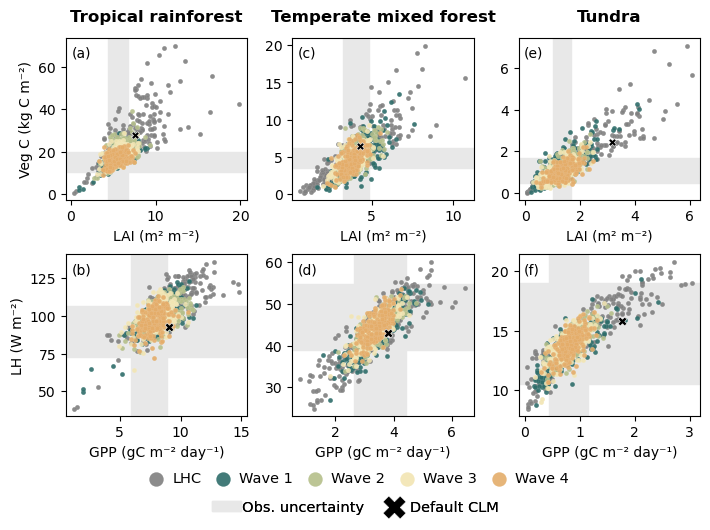

In [20]:
biomes = [1, 7, 13]
color_default='k'

colors = ['grey','#2E6D6A', '#B5BF8A','#F2E5B3', '#E4AD6A','slateblue','k']

wave_data = {
    'lhc':   {'label': 'LHC', 'color': colors[0]},
    'wave1': {'label': 'Wave 1',      'color': colors[1]},
    'wave2': {'label': 'Wave 2',      'color': colors[2]},
    'wave3': {'label': 'Wave 3',      'color': colors[3]},
    'wave4': {'label': 'Wave 4',      'color': colors[4]},
}

fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.8))

scatter_kw = dict(s=12, alpha=0.9, edgecolors='white', linewidths=0.05, rasterized=True)

panel_labels = [['(a)','(b)'],['(c)','(d)'],['(e)','(f)']]

for col, b in enumerate(biomes):

    ax = axes[0, col]

    ax.axvspan(obs.LAI_mean.isel(biome=b) - 3*obs.LAI_stdev.isel(biome=b),
               obs.LAI_mean.isel(biome=b) + 3*obs.LAI_stdev.isel(biome=b),
               color='#E8E8E8', zorder=0,
               label='Obs. uncertainty' if col == 0 else '')
    ax.axhspan(obs.TVC_mean.isel(biome=b) - 3*obs.TVC_stdev.isel(biome=b),
               obs.TVC_mean.isel(biome=b) + 3*obs.TVC_stdev.isel(biome=b),
               color='#E8E8E8', zorder=0)

    for key, (lai_d, tvc_d) in zip(wave_data.keys(), [
        (lai_biome_lhc, tvc_biome_lhc),
        (lai_biome_wave1, tvc_biome_wave1),
        (lai_biome_wave2, tvc_biome_wave2),
        (lai_biome_wave3, tvc_biome_wave3),
        (lai_biome_wave4, tvc_biome_wave4),
    ]):
        ax.scatter(lai_d.isel(biome=b), tvc_d.isel(biome=b),
                   color=wave_data[key]['color'], **scatter_kw,
                   label=wave_data[key]['label'] if col == 0 else '')

    ax.scatter(lai_biome_lhc.isel(biome=b, ens=0), tvc_biome_lhc.isel(biome=b, ens=0),
               color=color_default, s=30, marker='X', zorder=5, linewidths=0.4,
               edgecolors='white', label='Default CLM' if col == 0 else '')

    ax.set_title(biome_info[str(b)]['name'], fontsize=12, fontweight='bold',pad=12)
    ax.set_xlabel('LAI (m² m⁻²)')
    if col == 0:
        ax.set_ylabel('Veg C (kg C m⁻²)')
    ax.text(0.03, 0.95, panel_labels[col][0], transform=ax.transAxes, fontsize=10, va='top', ha='left')
    

    ax = axes[1, col]

    ax.axvspan(obs.GPP_mean.isel(biome=b) - 3*obs.GPP_stdev.isel(biome=b),
               obs.GPP_mean.isel(biome=b) + 3*obs.GPP_stdev.isel(biome=b),
               color='#E8E8E8', zorder=0)
    ax.axhspan(obs.LH_mean.isel(biome=b) - 3*obs.LH_stdev.isel(biome=b),
               obs.LH_mean.isel(biome=b) + 3*obs.LH_stdev.isel(biome=b),
               color='#E8E8E8', zorder=0)

    for key, (gpp_d, lh_d) in zip(wave_data.keys(), [
        (gpp_biome_lhc, lh_biome_lhc),
        (gpp_biome_wave1, lh_biome_wave1),
        (gpp_biome_wave2, lh_biome_wave2),
        (gpp_biome_wave3, lh_biome_wave3),
        (gpp_biome_wave4, lh_biome_wave4),
    ]):
        ax.scatter(gpp_d.isel(biome=b), lh_d.isel(biome=b),
                   color=wave_data[key]['color'], **scatter_kw,
                   label=wave_data[key]['label'] if col == 0 else '')

    ax.scatter(gpp_biome_lhc.isel(biome=b, ens=0), lh_biome_lhc.isel(biome=b, ens=0),
               edgecolors='white', color=color_default, s=40, marker='X', zorder=5, linewidths=0.4)

    ax.set_xlabel('GPP (gC m⁻² day⁻¹)')
    if col == 0:
        ax.set_ylabel('LH (W m⁻²)')

    ax.text(0.03, 0.95, panel_labels[col][1], transform=ax.transAxes, fontsize=10, va='top', ha='left')

handles, labels = axes[0, 0].get_legend_handles_labels()

leg1 = fig.legend([handles[0], handles[6]], [labels[0], labels[6]],
                  loc='lower center', ncol=2, frameon=False,
                  fontsize=10.5, markerscale=3, bbox_to_anchor=(0.5, -0.11),
                  handletextpad=0.1, columnspacing=1.0)

fig.legend(handles[1:6], labels[1:6],
           loc='lower center', ncol=5, frameon=False,
           fontsize=10.5, markerscale=3, bbox_to_anchor=(0.5, -0.05),
           handletextpad=0.1, columnspacing=0.5)

fig.add_artist(leg1) 

fig.tight_layout(rect=[0, 0, 1, 1], w_pad=0.3, h_pad=.5)
fig.savefig('../figs/figure3_hm_scatter.png', dpi=300, bbox_inches='tight')

### Histograms (Fig 7)

In [22]:
colors = ['grey','#2E6D6A', '#B5BF8A','#F2E5B3', '#E4AD6A','slateblue','k']

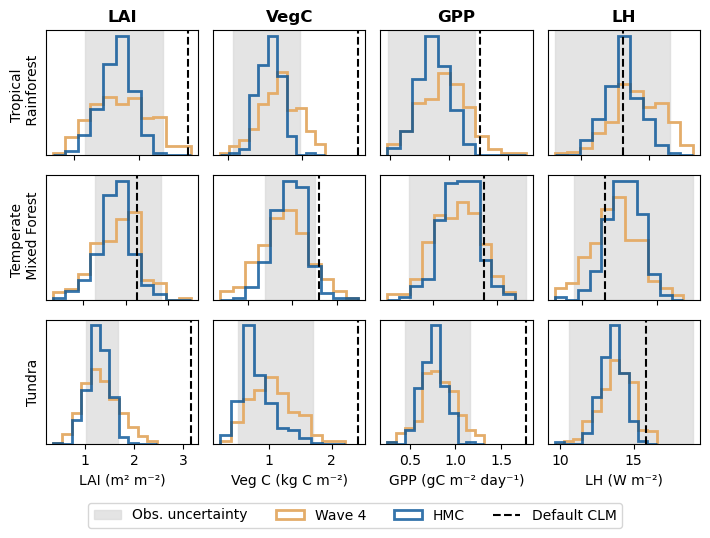

In [15]:
colors_hist = {
    'lhc':   'grey',   # 
    'wave4': '#E4AD6A',    # 
    'hmc':  '#025196' #'#9B6B9E',   
}
color_obs = '#D9D9D9'
color_default = 'k'

fig, axes = plt.subplots(3, 4, figsize=(7.2, 5.4))  

hist_kw = dict(histtype='step', linewidth=1.2, density=True)

variables = [
    ('LAI',  'lai', 'LAI (m² m⁻²)',           'LAI_mean', 'LAI_stdev'),
    ('VegC',  'tvc', 'Veg C (kg C m⁻²)',       'TVC_mean', 'TVC_stdev'),
    ('GPP',  'gpp', 'GPP (gC m⁻² day⁻¹)',     'GPP_mean', 'GPP_stdev'),
    ('LH',   'lh',  'LH (W m⁻²)',             'LH_mean',  'LH_stdev'),
]

biomes = [1, 7, 13]

for col, (vname, prefix, xlabel, obs_mean, obs_std) in enumerate(variables):
    for row, b in enumerate(biomes):
        ax = axes[row, col]

        # Obs uncertainty band
        mu = obs[obs_mean].isel(biome=b)
        sd = obs[obs_std].isel(biome=b)
        ax.axvspan(mu - 3*sd, mu + 3*sd, color=color_obs, zorder=0,alpha=0.7,
                   label='Obs. uncertainty' if (row == 0 and col == 0) else '')

        # Histograms
        data_lhc   = eval(f'{prefix}_biome_lhc').isel(biome=b)
        data_wave4 = eval(f'{prefix}_biome_wave4').isel(biome=b)
        data_hmc   = eval(f'{prefix}_biome_hmc').isel(biome=b)

        # bins
        all_data = np.concatenate([data_wave4.values.ravel(), data_hmc.values.ravel()])
        bins = np.linspace(np.nanmin(all_data), np.nanmax(all_data), 12)

        #ax.hist(data_lhc,   color=colors_hist['lhc'],   **hist_kw,
        #        label='LHC' if (row == 0 and col == 0) else '')
        ax.hist(data_wave4, bins=bins,  color=colors_hist['wave4'], density=True,alpha=1, histtype='step', linewidth=2, 
                label='Wave 4' if (row == 0 and col == 0) else '')
        ax.hist(data_hmc,  bins=bins,  color=colors_hist['hmc'],   density=True, alpha=0.8, histtype='step', linewidth=2, 
                label='HMC' if (row == 0 and col == 0) else '')

        # Default 
        ax.axvline(data_lhc.isel(ens=0), color=color_default, lw=1.5,
                   ls='--', zorder=5,
                   label='Default CLM' if (row == 0 and col == 0) else '')

        # Labels
        if row == len(biomes) - 1:
            ax.set_xlabel(xlabel)
        else:
            ax.set_xticklabels([])
        if row == 0:
            ax.set_title(vname, fontweight='bold')
        if (col == 0) & (row==0):
            ax.set_ylabel('Tropical \n Rainforest')
        if (col == 0) & (row==1):
            ax.set_ylabel('Temperate \n Mixed Forest')
        if (col == 0) & (row==2):
            ax.set_ylabel('Tundra')
        ax.set_yticks([])  # density axis ticks rarely useful

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5,
           frameon=True, fontsize=10, bbox_to_anchor=(0.5, 0.0))

fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig('../figs/figure7_hist_biomes_W4+wHMC.png', dpi=300, bbox_inches='tight')

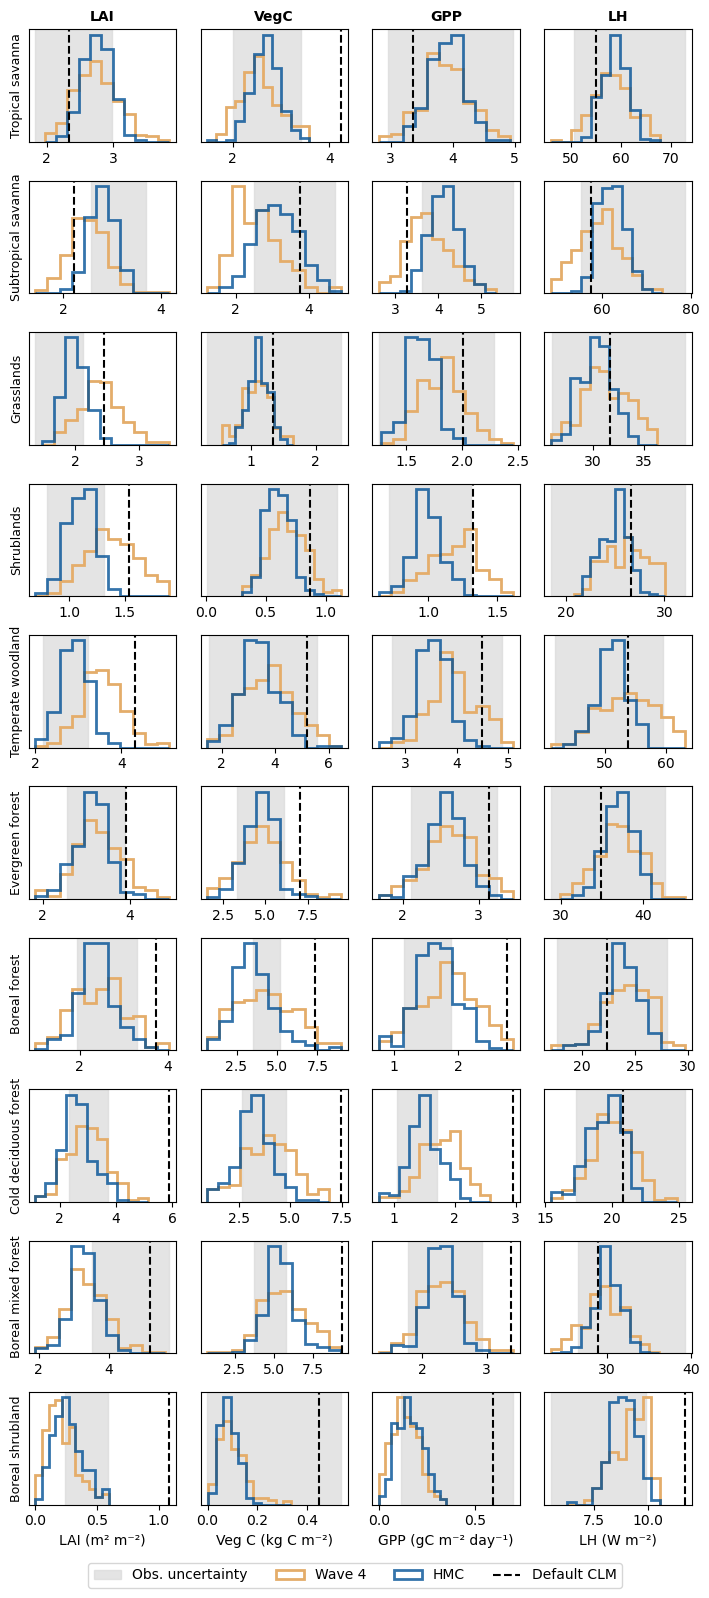

In [17]:
colors_hist = {
    'lhc':   'grey',   # 
    'wave4': '#E4AD6A',    # 
    'hmc':  '#025196' #'#9B6B9E',   
}
color_obs = '#D9D9D9'
color_default = 'k'

fig, axes = plt.subplots(10, 4, figsize=(7.2, 16))  

hist_kw = dict(histtype='step', linewidth=1.2, density=True)

variables = [
    ('LAI',  'lai', 'LAI (m² m⁻²)',           'LAI_mean', 'LAI_stdev'),
    ('VegC',  'tvc', 'Veg C (kg C m⁻²)',       'TVC_mean', 'TVC_stdev'),
    ('GPP',  'gpp', 'GPP (gC m⁻² day⁻¹)',     'GPP_mean', 'GPP_stdev'),
    ('LH',   'lh',  'LH (W m⁻²)',             'LH_mean',  'LH_stdev'),
]

biomes = [2,3,4,5,6,8,9,10,11,12]

for col, (vname, prefix, xlabel, obs_mean, obs_std) in enumerate(variables):
    for row, b in enumerate(biomes):
        ax = axes[row, col]

        # Obs uncertainty band
        mu = obs[obs_mean].isel(biome=b)
        sd = obs[obs_std].isel(biome=b)
        ax.axvspan(mu - 3*sd, mu + 3*sd, color=color_obs, zorder=0,alpha=0.7,
                   label='Obs. uncertainty' if (row == 0 and col == 0) else '')

        # Histograms — all as step outlines
        data_lhc   = eval(f'{prefix}_biome_lhc').isel(biome=b)
        data_wave4 = eval(f'{prefix}_biome_wave4').isel(biome=b)
        data_hmc   = eval(f'{prefix}_biome_hmc').isel(biome=b)

        # compute bins
        all_data = np.concatenate([data_wave4.values.ravel(), data_hmc.values.ravel()])
        bins = np.linspace(np.nanmin(all_data), np.nanmax(all_data), 12)

        #ax.hist(data_lhc,   color=colors_hist['lhc'],   **hist_kw,
        #        label='LHC' if (row == 0 and col == 0) else '')
        ax.hist(data_wave4, bins=bins,  color=colors_hist['wave4'], density=True,alpha=1, histtype='step', linewidth=2, 
                label='Wave 4' if (row == 0 and col == 0) else '')
        ax.hist(data_hmc,  bins=bins,  color=colors_hist['hmc'],   density=True, alpha=0.8, histtype='step', linewidth=2, 
                label='HMC' if (row == 0 and col == 0) else '')

        # Default model
        ax.axvline(data_lhc.isel(ens=0), color=color_default, lw=1.5,
                   ls='--', zorder=5,
                   label='Default CLM' if (row == 0 and col == 0) else '')

        # Labels
        if row == len(biomes) - 1:
            ax.set_xlabel(xlabel,fontsize=10)
        #else:
            #ax.set_xticklabels([])
        if row == 0:
            ax.set_title(vname, fontweight='bold',fontsize=10)
        if (col == 0):
            ax.set_ylabel(biome_info[str(b)]['name'],fontsize=9)
        ax.set_yticks([])  # density axis ticks rarely useful

# Shared legend at top
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5,
           frameon=True, fontsize=10, bbox_to_anchor=(0.5, 0.0))

fig.tight_layout(rect=[0, 0.02, 1, 1])
fig.savefig('../figs/SI_figS12_hist_biomes_wave4_HMC.png', dpi=300, bbox_inches='tight')